# Task 3 – Object Recognition: Viola–Jones (Haar) vs YOLO (Unit 5)

**Inputs:** my two photographs and frames from my self-recorded video (a man breaking a coconut in front of a new car decorated with a flower garland)

**What this notebook does**
1. Applies pretrained **Haar cascade** classifiers (Viola–Jones) to detect faces, eyes and full bodies
2. Applies a pretrained **YOLOv8n** model to detect objects
3. Displays bounding boxes, class labels and confidence scores
4. Compares the two detectors
5. Identifies cases where a detector **misses** an object or makes an **incorrect** detection

Outputs are saved to `outputs/task3/`.

## 0. Setup

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
OUT = "outputs/task3"
os.makedirs(OUT, exist_ok=True)


def show(images, titles, cols=3, size=4.0, suptitle=None, save_as=None):
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size * h / w + 0.45) + 0.5))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(f"{OUT}/{save_as}", dpi=110)
    plt.show()


def load(path, width=750):
    im = cv2.imread(path)
    return cv2.resize(im, (width, int(im.shape[0] * width / im.shape[1])), interpolation=cv2.INTER_AREA)


def put_label(img, text, x, y, col):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
    y = max(y, th + 6)
    cv2.rectangle(img, (x, y - th - 6), (x + tw + 4, y), col, -1)
    cv2.putText(img, text, (x + 2, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)

## 1. Viola–Jones detector (Haar cascades)
The Viola–Jones method (2001):
- **Haar-like features:** simple rectangle patterns (light/dark) measured very quickly with an *integral image*.
- **AdaBoost** selects the most useful features out of many thousands.
- A **cascade** of stages rejects non-face windows early, so only promising windows reach the later stages. This makes it fast on a CPU.
- It slides a window over the image at many scales (`scaleFactor`). `minNeighbors` sets how many overlapping detections are needed to accept one.

It gives **only a box, no class probability or confidence score**, and each cascade detects only the single object type it was trained on.

The cascade XML files are in `models/`. Newer OpenCV versions no longer bundle them inside `cv2.data`.

In [2]:
def load_cascade(fname):
    for folder in ["models", getattr(getattr(cv2, "data", None), "haarcascades", "")]:
        c = cv2.CascadeClassifier(os.path.join(folder, fname))
        if not c.empty():
            return c
    raise FileNotFoundError(fname)


cascades = {
    "face": load_cascade("haarcascade_frontalface_default.xml"),
    "eye": load_cascade("haarcascade_eye.xml"),
    "fullbody": load_cascade("haarcascade_fullbody.xml"),
}
params = {
    "face": dict(scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)),
    "eye": dict(scaleFactor=1.1, minNeighbors=8, minSize=(12, 12)),
    "fullbody": dict(scaleFactor=1.05, minNeighbors=3, minSize=(60, 120)),
}
colours = {"face": (0, 255, 0), "eye": (255, 200, 0), "fullbody": (255, 0, 255)}


def run_haar(img, which):
    gray = cv2.equalizeHist(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
    vis, counts = img.copy(), {}
    t = time.perf_counter()
    for name in which:
        boxes = cascades[name].detectMultiScale(gray, **params[name])
        counts[name] = len(boxes)
        for (x, y, w, h) in boxes:
            cv2.rectangle(vis, (x, y), (x + w, y + h), colours[name], 2)
            put_label(vis, name, x, y, colours[name])
    return vis, counts, (time.perf_counter() - t) * 1000

## 2. YOLO (You Only Look Once)
YOLOv8n ("nano") is a convolutional neural network trained on the **COCO dataset (80 classes)**, including person, car, truck, chair and potted plant.
- It processes the **whole image in one forward pass** and predicts boxes, class labels and a **confidence score** for each.
- Non-maximum suppression removes duplicate boxes.
- I use a confidence threshold of 0.25.

The weights (`yolov8n.pt`, 6 MB) download automatically the first time.

In [3]:
yolo = YOLO("yolov8n.pt")
CONF = 0.25
print("YOLO can detect", len(yolo.names), "classes, e.g.:", list(yolo.names.values())[:12], "...")


def run_yolo(img):
    t = time.perf_counter()
    r = yolo(img, conf=CONF, verbose=False)[0]
    ms = (time.perf_counter() - t) * 1000
    vis, dets = img.copy(), []
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0])
        name, conf = yolo.names[int(b.cls)], float(b.conf)
        dets.append((name, conf))
        col = (0, 255, 0) if name == "person" else (255, 120, 0) if name == "car" else (0, 200, 255)
        cv2.rectangle(vis, (x1, y1), (x2, y2), col, 2)
        put_label(vis, f"{name} {conf:.2f}", x1, y1, col)
    return vis, dets, ms


def describe(dets):
    out = {}
    for n, c in dets:
        out.setdefault(n, []).append(c)
    return "; ".join(f"{n} ×{len(c)} ({', '.join(f'{v:.2f}' for v in c)})" for n, c in out.items()) or "none"


_ = run_yolo(load("data/photo1.jpg"))   # warm-up run so the timings below are fair

YOLO can detect 80 classes, e.g.: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign'] ...


## 3. Detection on the photographs

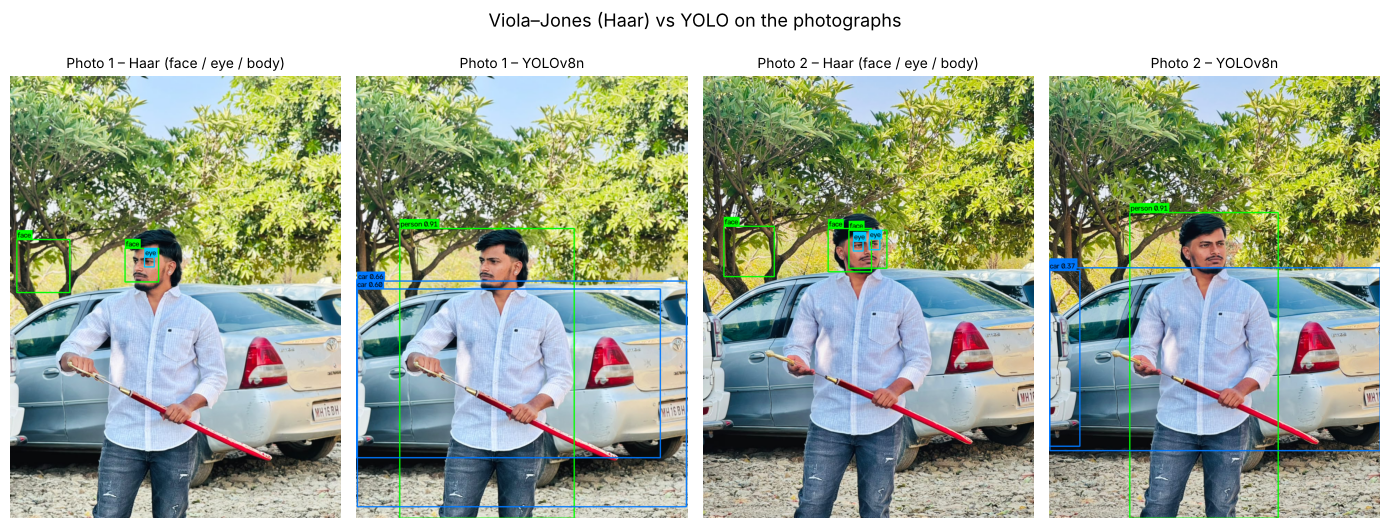

In [4]:
rows, figs, titles = [], [], []
for name, path in [("Photo 1", "data/photo1.jpg"), ("Photo 2", "data/photo2.jpg")]:
    img = load(path)
    hv, counts, hms = run_haar(img, ["face", "eye", "fullbody"])
    yv, dets, yms = run_yolo(img)
    tag = name.replace(" ", "").lower()
    cv2.imwrite(f"{OUT}/haar_{tag}.jpg", hv)
    cv2.imwrite(f"{OUT}/yolo_{tag}.jpg", yv)
    figs += [hv, yv]
    titles += [f"{name} – Haar (face / eye / body)", f"{name} – YOLOv8n"]
    rows.append([name, "Haar cascades", ", ".join(f"{k}: {v}" for k, v in counts.items()), "No", round(hms)])
    rows.append([name, "YOLOv8n", describe(dets), "Yes", round(yms)])

show(figs, titles, cols=4, size=3.5, suptitle="Viola–Jones (Haar) vs YOLO on the photographs",
     save_as="fig1_photos_haar_vs_yolo.png")

## 4. Detection on video frames
The video shows a person moving around a new car: crouching, bending, throwing and standing. On these frames I run the **face** and **full-body** Haar cascades and compare them with YOLO. The frames show the person in poses Haar was not trained for (crouching, side view, face looking down).

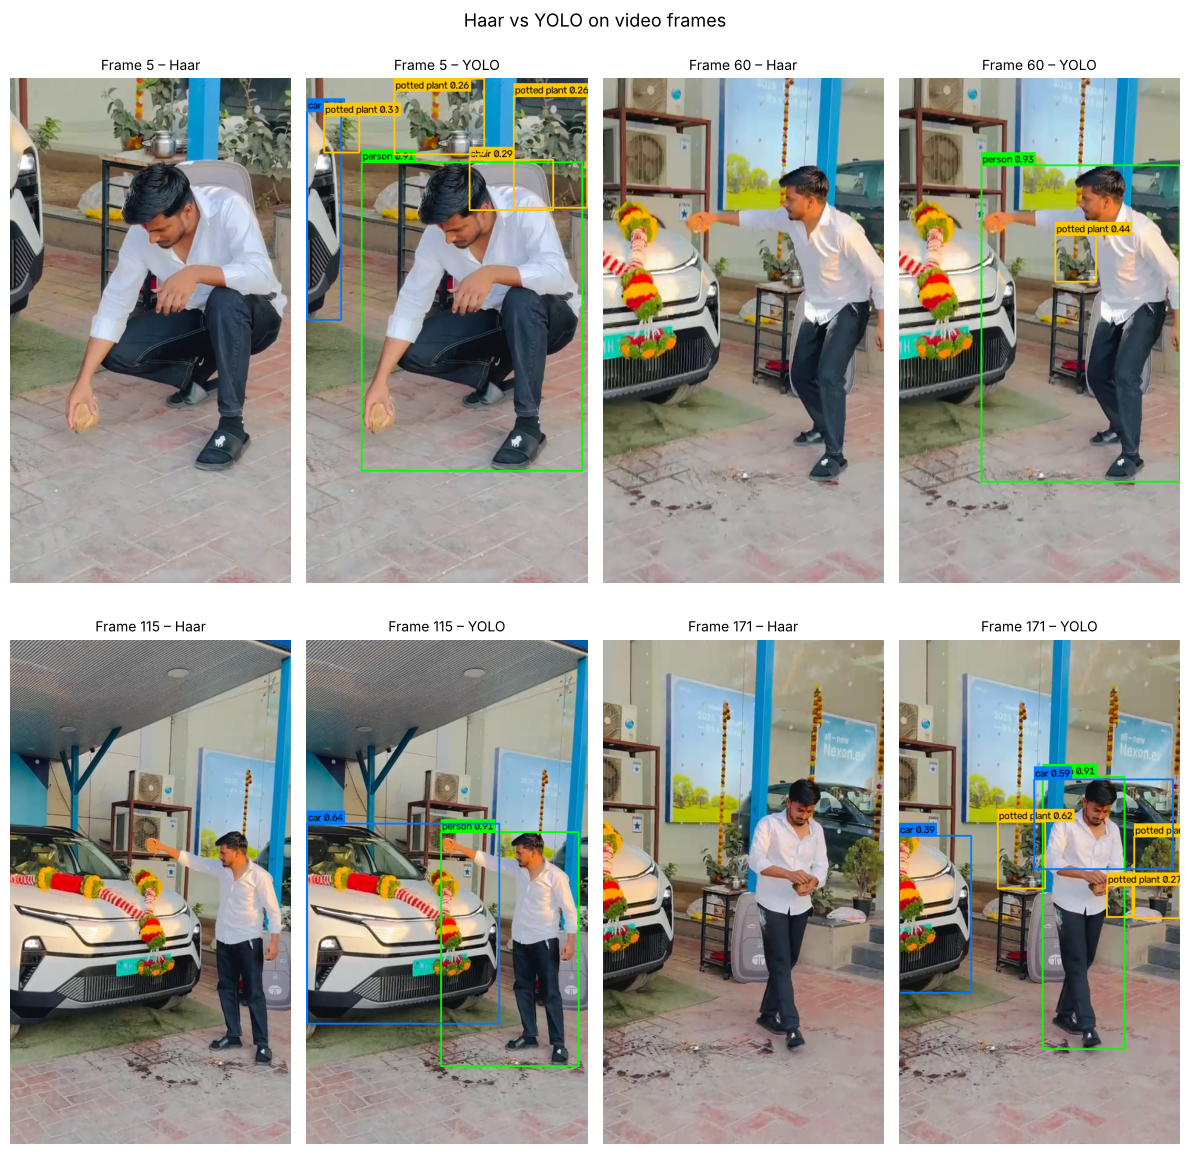

In [5]:
cap = cv2.VideoCapture("data/video.mp4")
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frame_ids = np.linspace(5, total - 5, 4).astype(int)
figs, titles = [], []
for i in frame_ids:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    hv, counts, hms = run_haar(frame, ["face", "fullbody"])
    yv, dets, yms = run_yolo(frame)
    cv2.imwrite(f"{OUT}/frame{i:03d}_haar.jpg", hv)
    cv2.imwrite(f"{OUT}/frame{i:03d}_yolo.jpg", yv)
    figs += [hv, yv]
    titles += [f"Frame {i} – Haar", f"Frame {i} – YOLO"]
    rows.append([f"Video frame {i}", "Haar cascades", ", ".join(f"{k}: {v}" for k, v in counts.items()), "No", round(hms)])
    rows.append([f"Video frame {i}", "YOLOv8n", describe(dets), "Yes", round(yms)])
cap.release()
show(figs, titles, cols=4, size=3.0, suptitle="Haar vs YOLO on video frames", save_as="fig2_video_haar_vs_yolo.png")

## 5. Detection results table

In [6]:
table_det = pd.DataFrame(rows, columns=["Input", "Detector", "Detections (confidence)", "Gives confidence?", "Time (ms)"])
table_det.to_csv(f"{OUT}/table_detections.csv", index=False)
pd.set_option("display.max_colwidth", 80)
table_det

,Input,Detector,Detections (confidence),Gives confidence?,Time (ms)
0,Photo 1,Haar cascades,"face: 2, eye: 1, fullbody: 0",No,1285
1,Photo 1,YOLOv8n,"person ×1 (0.91); car ×2 (0.66, 0.60)",Yes,156
2,Photo 2,Haar cascades,"face: 3, eye: 2, fullbody: 0",No,1223
3,Photo 2,YOLOv8n,"person ×1 (0.91); car ×2 (0.65, 0.37)",Yes,89
4,Video frame 5,Haar cascades,"face: 0, fullbody: 0",No,269
5,Video frame 5,YOLOv8n,"person ×1 (0.91); car ×1 (0.48); potted plant ×3 (0.30, 0.26, 0.26); chair ×...",Yes,68
6,Video frame 60,Haar cascades,"face: 0, fullbody: 0",No,272
7,Video frame 60,YOLOv8n,person ×1 (0.93); potted plant ×1 (0.44),Yes,56
8,Video frame 115,Haar cascades,"face: 0, fullbody: 0",No,238
9,Video frame 115,YOLOv8n,person ×1 (0.91); car ×1 (0.64),Yes,53


## 6. YOLO on every frame of the video
To measure how consistent YOLO is, I run it on all frames and save an annotated video (`yolo_video_annotated.mp4`).

In [7]:
cap = cv2.VideoCapture("data/video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w, h = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter(f"{OUT}/yolo_video_annotated.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
n, person_frames, person_conf, others, times, examples = 0, 0, [], {}, [], []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    vis, dets, ms = run_yolo(frame)
    writer.write(vis)
    times.append(ms)
    p = [c for name, c in dets if name == "person"]
    if p:
        person_frames += 1
        person_conf.append(max(p))
    for name, c in dets:
        if name != "person":
            others[name] = others.get(name, 0) + 1
            if name not in [e[2] for e in examples]:      # keep one example frame per extra class
                examples.append((n, vis, name))
    n += 1
cap.release(); writer.release()

table_video = pd.DataFrame([
    ["Frames processed", n],
    ["Frames with 'person' detected", f"{person_frames} ({100 * person_frames / n:.1f}%)"],
    ["Mean / min person confidence", f"{np.mean(person_conf):.2f} / {np.min(person_conf):.2f}"],
    ["Other classes detected (number of frames)", ", ".join(f"{k}: {v}" for k, v in sorted(others.items(), key=lambda x: -x[1]))],
    ["Mean YOLO time per frame (CPU)", f"{np.mean(times):.0f} ms"],
], columns=["Metric", "Value"])
table_video.to_csv(f"{OUT}/table_video_yolo.csv", index=False)
table_video

,Metric,Value
0,Frames processed,176
1,Frames with 'person' detected,176 (100.0%)
2,Mean / min person confidence,0.90 / 0.77
3,Other classes detected (number of frames),"car: 140, potted plant: 125, chair: 37, couch: 35, boat: 7, truck: 7, suitca..."
4,Mean YOLO time per frame (CPU),57 ms


### Examples of incorrect YOLO detections
Besides "person", YOLO reported several other classes in the video (see the table above). **"car"** and **"potted plant"** are mostly correct: the new car and the plants on the stand. I checked the rest frame by frame, and these are **wrong**:
- **"boat"** and **"truck"**: the new car decorated with the flower garland
- **"tv"**: the outdoor AC unit on the wall (a rectangular box with a grille)
- **"skateboard"**: the person's black slipper

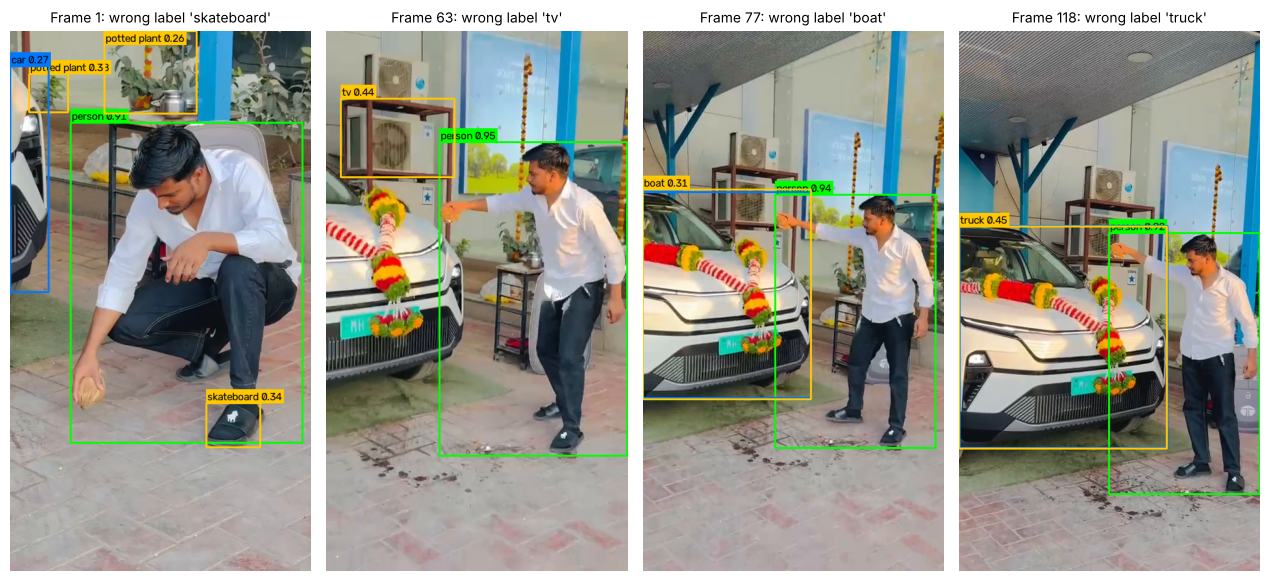

In [8]:
for i, v, lbl in examples:          # save one example frame for every extra class
    cv2.imwrite(f"{OUT}/yolo_extra_{lbl.replace(' ', '_')}_frame{i:03d}.jpg", v)

wrong = ["boat", "truck", "tv", "skateboard"]   # labels I checked by eye and found to be wrong
wrong_examples = [e for e in examples if e[2] in wrong]
show([v for _, v, _ in wrong_examples], [f"Frame {i}: wrong label '{lbl}'" for i, _, lbl in wrong_examples],
     cols=len(wrong_examples), size=3.2, save_as="fig3_yolo_errors.png")

## 7. Comparison and error analysis

**Misses and incorrect detections that I found:**

| Case | Detector | What happened | Likely reason |
|---|---|---|---|
| Photo 1 and 2 | Haar face | A "face" detected in the **tree leaves** (top-left) (**false positive**) | A light/dark leaf pattern that resembles the Haar face template |
| Photo 2 | Haar face | **Two overlapping face boxes** on the same face (duplicate) | Neighbouring windows at different scales were not merged |
| Photo 1 and 2 | Haar full body | Person **not detected** (**miss**) | The arms hold a sword across the body, so the silhouette doesn't match the trained upright pedestrian shape |
| All 4 video frames | Haar face and full body | **Nothing detected** at all (**miss**) | The face looks down or sideways, the body is crouching or bending, and the face is small in the frame |
| Photos | YOLO | The **sword is not detected** (**miss**) | "Sword" is not one of the 80 COCO classes, so YOLO cannot recognise it |
| Photo 1 | YOLO | The same silver car detected **twice** ("car" 0.66 and 0.60) | Overlapping boxes with different extents survived non-maximum suppression |
| Video, 7 frames each | YOLO | New car with garland labelled **"boat"** or **"truck"** | Unusual decoration and front view; similar large vehicle-like shapes |
| Video, 2 frames | YOLO | AC outdoor unit labelled **"tv"** | Rectangular box shape on the wall |
| Video, 2 frames | YOLO | Black slipper labelled **"skateboard"** (0.34) | Small dark object on the ground, seen at a low angle |

**Overall comparison:**

| Aspect | Viola–Jones (Haar) | YOLOv8n |
|---|---|---|
| Method | Hand-crafted Haar features + AdaBoost cascade | Deep CNN, single forward pass |
| Classes | One per cascade (face, eye, body…) | 80 COCO classes at once |
| Output | Box only, **no confidence** | Box + class label + **confidence score** |
| Accuracy here | Found the frontal face in the photos but with false positives; detected nothing in the video frames | Person found in **100% of video frames** (mean confidence 0.90, minimum 0.77) and in both photos (0.91) |
| Robustness | Needs a frontal, upright, well-lit pose | Handles crouching, bending and side views |
| Speed / hardware | Light and simple; no GPU needed | Heavier (needs PyTorch) but about 60 ms per frame on a laptop CPU |

**Conclusion:** Haar cascades only work in the conditions they were trained for (frontal face, upright full body). In my video the person is crouching, bending and looking away, and Haar missed him in every tested frame. YOLO detected the person in every single frame with high confidence, and also found the cars and plants. Its errors were (1) objects that are not in its 80 classes (the sword) and (2) confusing unusual-looking objects with similar classes (decorated car → boat/truck, AC unit → tv, slipper → skateboard).